In [15]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import anndata as ad
import h5py

In [19]:
expression_matrix_path = "/g/kreshuk/buglakova/projects/platy_registration/data/pipeline_output/aggregated_expression/expression_matrix_aggregated.tsv"
df = pd.read_csv(expression_matrix_path, sep="\t")
columns = [col for col in df.columns if col.endswith("spots")]
df_expr = df[columns]

In [20]:
df_expr.head()

,Arx_spots,Brn3_spots,Bsx_AP203_spots,COpsin1_spots,Dbx_AP080_spots,FoxQ2_AP249_spots,GoOpsin1_AP127_spots,Hoxa1_AP181_spots,Msx_AP009_spots,NCALD_spots,OTX_spots,Phc2_AP156_spots,Pkd1_spots,Prox_spots,Ptf1_spots,ROpsin_spots,Vglut_AP173_spots
0,5.0,9.0,0.0,9.0,22.0,2.0,2.0,14.0,6.0,8.0,2.0,23.0,22.0,9.0,3.0,25.0,20.0
1,27.0,10.0,1.0,3.0,3.0,1.0,1.0,5.0,2.0,7.0,9.0,46.0,18.0,6.0,1.0,15.0,34.0
2,18.0,17.0,0.0,5.0,1.0,2.0,1.0,4.0,3.0,13.0,6.0,31.0,15.0,16.0,1.0,12.0,30.0
3,24.0,7.0,0.0,3.0,1.0,2.0,3.0,18.0,2.0,7.0,5.0,34.0,16.0,11.0,9.0,17.0,26.0
4,22.0,30.0,1.0,4.0,2.0,0.0,6.0,2.0,3.0,3.0,14.0,18.0,10.0,13.0,5.0,12.0,17.0


In [28]:
df_expr.sum(axis=0)

Arx_spots               101843.0
Brn3_spots              108381.0
Bsx_AP203_spots          34798.0
COpsin1_spots            33925.0
Dbx_AP080_spots          16388.0
FoxQ2_AP249_spots        27153.0
GoOpsin1_AP127_spots     43779.0
Hoxa1_AP181_spots        76310.0
Msx_AP009_spots          60316.0
NCALD_spots              81744.0
OTX_spots                45437.0
Phc2_AP156_spots        241419.0
Pkd1_spots               63998.0
Prox_spots              116643.0
Ptf1_spots               56878.0
ROpsin_spots            118659.0
Vglut_AP173_spots       130887.0
dtype: float64

(array([6.500e+01, 2.670e+02, 5.540e+02, 9.610e+02, 1.156e+03, 1.327e+03,
        1.153e+03, 1.042e+03, 8.020e+02, 7.310e+02, 5.450e+02, 4.340e+02,
        3.920e+02, 3.800e+02, 2.850e+02, 2.180e+02, 1.870e+02, 1.400e+02,
        1.270e+02, 9.100e+01, 8.300e+01, 6.400e+01, 4.400e+01, 4.300e+01,
        3.500e+01, 3.200e+01, 1.800e+01, 2.300e+01, 1.800e+01, 1.400e+01,
        1.400e+01, 1.600e+01, 2.500e+01, 7.000e+00, 1.900e+01, 1.100e+01,
        1.100e+01, 1.000e+01, 1.100e+01, 4.000e+00, 1.000e+01, 8.000e+00,
        1.300e+01, 5.000e+00, 1.100e+01, 5.000e+00, 7.000e+00, 5.000e+00,
        2.000e+00, 3.000e+00, 1.000e+01, 6.000e+00, 5.000e+00, 0.000e+00,
        1.000e+00, 1.000e+00, 4.000e+00, 2.000e+00, 4.000e+00, 0.000e+00,
        2.000e+00, 2.000e+00, 0.000e+00, 1.000e+00, 1.000e+00, 1.000e+00,
        0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 2.000e+00, 1.000e+00, 0.000e+00,
        1.000e+00, 0.000e+00, 0.000e+0

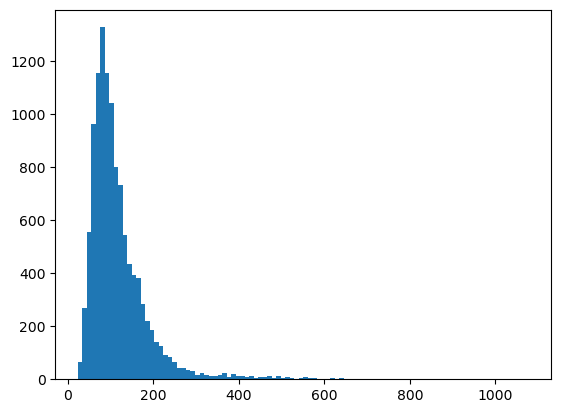

In [30]:
plt.hist(df_expr.sum(axis=1), bins=100)

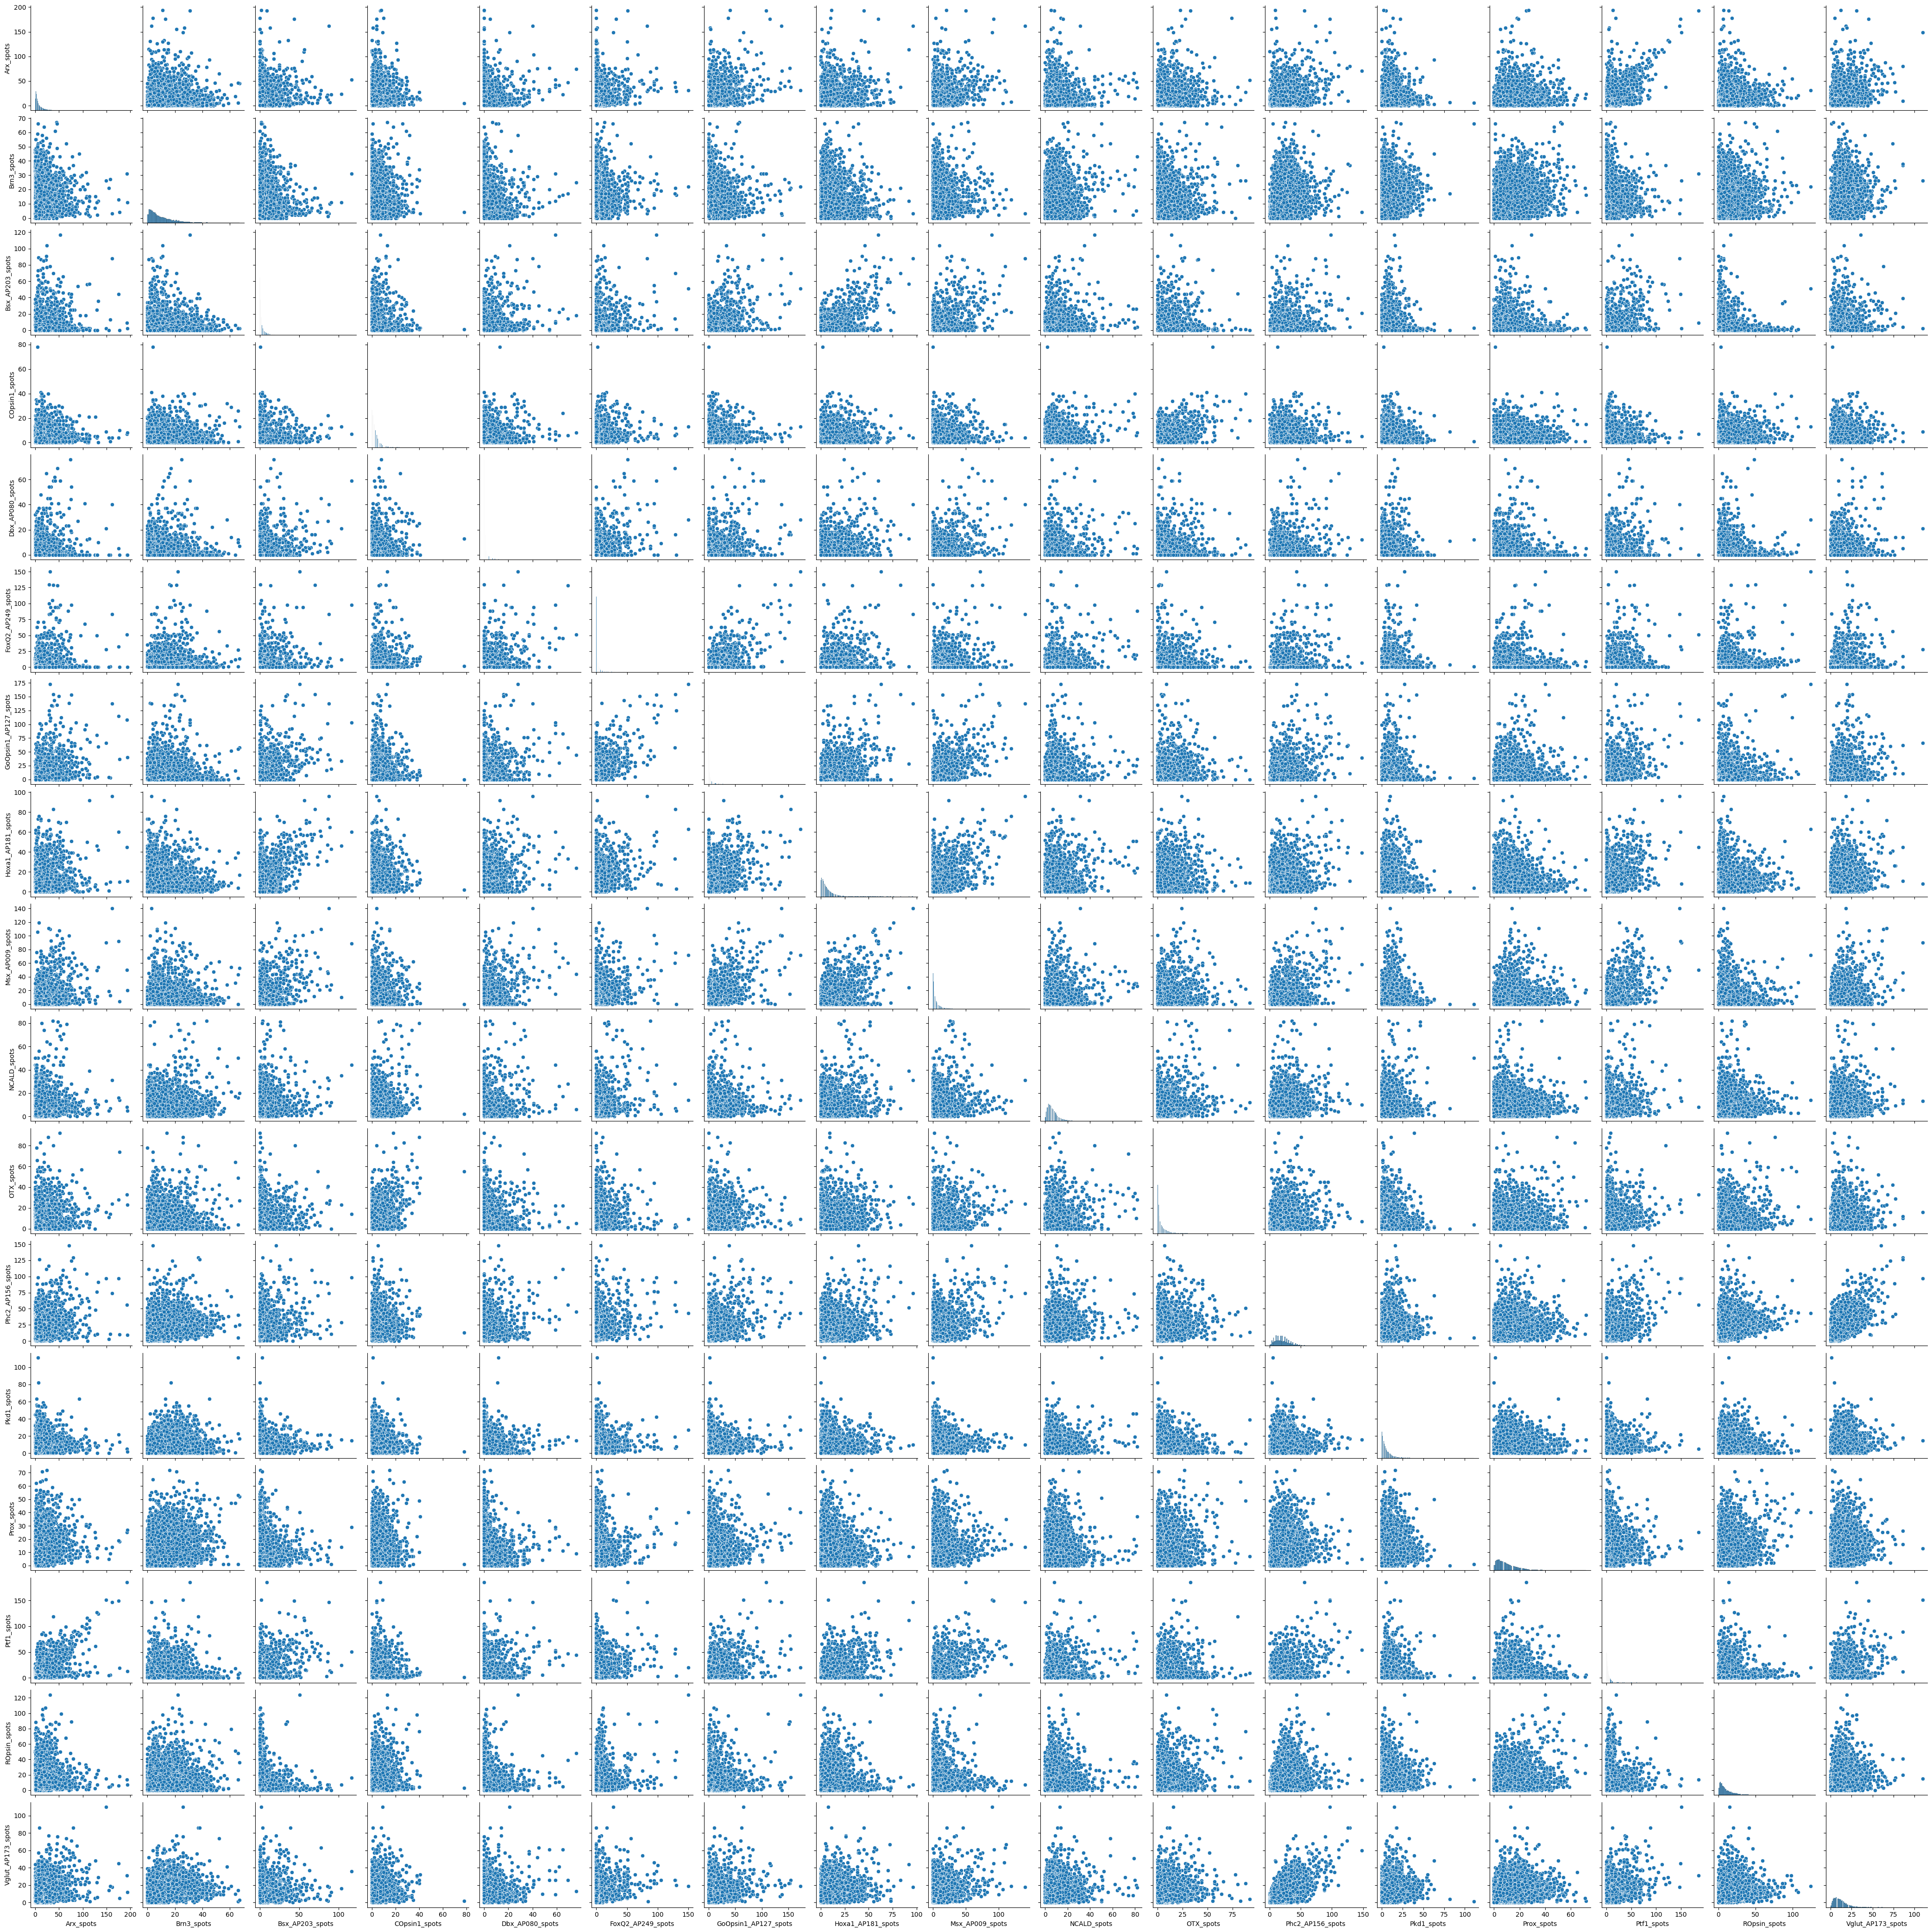

In [27]:
sns.pairplot(df_expr)

In [21]:
gene_names = [col.split("_")[0] for col in columns]
gene_names

['Arx',
 'Brn3',
 'Bsx',
 'COpsin1',
 'Dbx',
 'FoxQ2',
 'GoOpsin1',
 'Hoxa1',
 'Msx',
 'NCALD',
 'OTX',
 'Phc2',
 'Pkd1',
 'Prox',
 'Ptf1',
 'ROpsin',
 'Vglut']

In [22]:
adata = ad.AnnData(df_expr)
adata

/home/buglakov/miniconda3/envs/scrnaseq/lib/python3.12/site-packages/anndata/_core/anndata.py:183: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


AnnData object with n_obs × n_vars = 11477 × 17

In [23]:
adata.obs_names = df["label_id"]
adata_var_names = gene_names

/home/buglakov/miniconda3/envs/scrnaseq/lib/python3.12/site-packages/anndata/_core/anndata.py:933: UserWarning: 
AnnData expects .obs.index to contain strings, but got values like:
    [1, 2, 3, 4, 5]

    Inferred to be: integer

  names = self._prep_dim_index(names, "obs")


In [24]:
adata

AnnData object with n_obs × n_vars = 11477 × 17

In [31]:
adata.obs["total_counts"] = adata.X.sum(axis=1)

In [34]:
adata.obs[adata.obs["total_counts"] > 800]

,total_counts
label_id,
147,822.0
4106,816.0
4152,899.0
7801,1078.0
7802,829.0
8085,920.0
8100,923.0
8380,851.0


In [ ]:
adata[8085]

In [32]:
sc.tl.pca(adata)

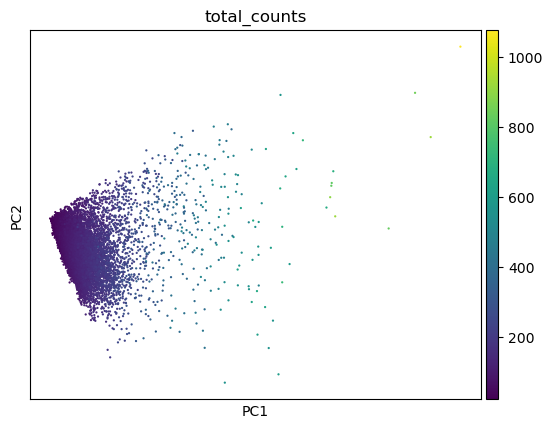

In [33]:
sc.pl.pca(
    adata, color="total_counts"
)